# 08 — Comprehensive Model Comparison & Benchmarks
Compares **Rule-Based**, **PPO Safe RL**, and **Soft Actor-Critic (SAC)** controllers across:
- Fuel consumption (Litres) and Fuel Savings (%)
- Reliability and Critical Load Protection (%)
- Renewable Utilization Rate (%)
- Battery Throughput and Cycle Degradation
- Total Operating Cost ($ USD)


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))


In [2]:
comp_path = PROJECT_ROOT / "results" / "comparison" / "controller_comparison.csv"
df_comp = pd.read_csv(comp_path)
df_comp


,controller,total_fuel_litres,total_cost_usd,total_unmet_kwh,renewable_utilization_pct,reliability_pct,diesel_run_hours,diesel_startups,battery_throughput_kwh,soc_boundary_events,avg_cost_per_hour,fuel_savings_vs_baseline_pct
0,Rule-Based,11441.86,31382.30,0.00,43.18,100.0000,704,27,13033.25,1395,15.6912,0.00
1,PPO,12215.00,33945.16,7.42,43.18,99.9919,859,38,13033.25,1395,16.9726,-6.76
2,SAC,11960.00,33604.66,7.42,43.18,99.9919,808,68,13033.25,1395,16.8023,-4.53


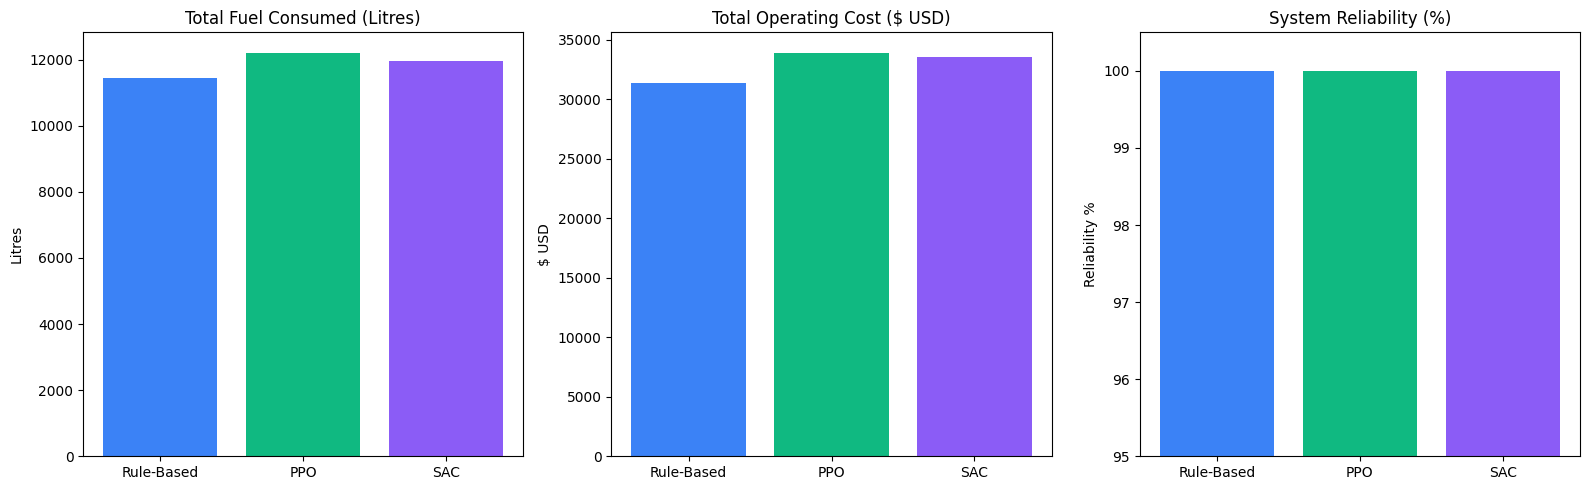

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Fuel
axes[0].bar(df_comp['controller'], df_comp['total_fuel_litres'], color=['#3b82f6', '#10b981', '#8b5cf6'])
axes[0].set_title("Total Fuel Consumed (Litres)")
axes[0].set_ylabel("Litres")

# Cost
axes[1].bar(df_comp['controller'], df_comp['total_cost_usd'], color=['#3b82f6', '#10b981', '#8b5cf6'])
axes[1].set_title("Total Operating Cost ($ USD)")
axes[1].set_ylabel("$ USD")

# Reliability
axes[2].bar(df_comp['controller'], df_comp['reliability_pct'], color=['#3b82f6', '#10b981', '#8b5cf6'])
axes[2].set_title("System Reliability (%)")
axes[2].set_ylim(95, 100.5)
axes[2].set_ylabel("Reliability %")

plt.tight_layout()
plt.show()
